# **Laboratorio de Procesamiento Digital de Imágenes (PDI)**

Pablo Andrés Villarreal Cárdenas - 2043233

Alan Zahir Lopez Rodriguez - 2103115

# **Práctica 7. Segmentación óptima**

**Importación de librerías**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

Se realiza la importación de librerías necesarias para llevar a cabo la práctica. OpenCV (cv2) se encarga del procesamiento y las transformaciones realizadas en las imágenes, mientras que Numpy es utilizado para la manipulación de matrices numéricas y Matplotlib para lograr visualizar los resultados de cada transformación.

Por su parte, de la librería SciPy se importó la función "minimize", el cual se utiliza para encontrar el valor óptimo de un parámetro minimizando una función objetivo.

# **Parte I.- Segmentación óptima**

**Segmentación sencilla**

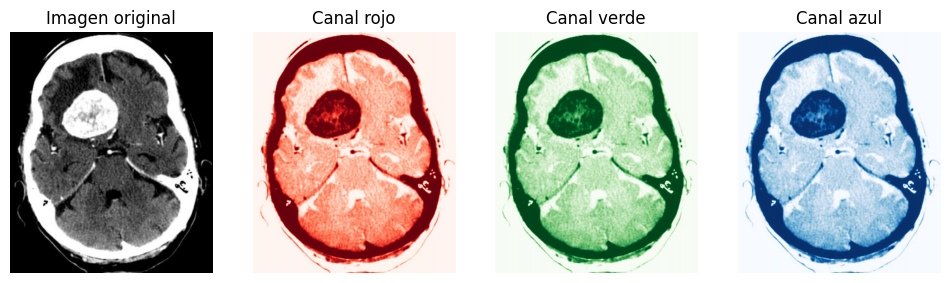

In [ ]:
# Cargar la imagen a color seleccionada
imagen = cv2.imread("/content/Te-me_0015.jpg")
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB) # Convertir de BGR a RGB

# Separar los canales R, G y B
R, G, B = imagen_rgb[:,:,0], imagen_rgb[:,:,1], imagen_rgb[:,:,2]

# Mostrar cada canal separado junto con la imagen original
plt.figure(figsize = (12, 4))
plt.subplot(1, 4, 1)
plt.imshow(imagen_rgb, cmap = 'gray')
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(R, cmap = 'Reds')
plt.title("Canal rojo")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(G, cmap = 'Greens')
plt.title("Canal verde")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(B, cmap = 'Blues')
plt.title("Canal azul")
plt.axis("off")
plt.show()

Primeramente se carga la imagen a través de "cv2.imread()" y debido a que OpenCV guarda los canales de color en el orden de BGR, es necesario convertirlo a RGB con ayuda de "cv2.cvtColor()".

Posteriormente, los canales rojo, verde y azul se separan y se guardan cada uno en una matriz bidimensional con valores de intensidad desde 0 a 255.

Por último, con matplotlib se muestran las 4 imágenes obtenidas: la original y cada canal por separado.

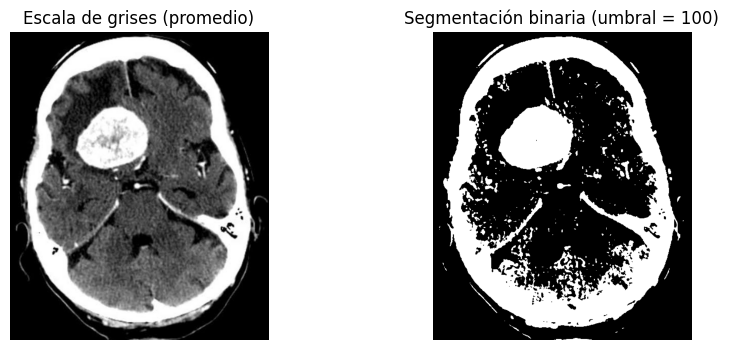

In [ ]:
# Realizar un promedio de los canales para pasar a escala de grises
gray_promedio = ((R.astype(np.float32) + G + B)/3).astype(np.uint8)

# Definir un umbral para la segmentación
umbral = 100
_, segmentada = cv2.threshold(gray_promedio, umbral, 255, cv2.THRESH_BINARY)

# Mostrar resultados
plt.figure(figsize = (10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray_promedio, cmap = 'gray')
plt.title("Escala de grises (promedio)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmentada, cmap = 'gray')
plt.title(f"Segmentación binaria (umbral = {umbral})")
plt.axis("off")
plt.show()

Para pasar la imagen a escala de grises se realiza un promedio de los 3 canales, después, se aplica una segmentación a la imagen en escala de grises con "cv2.threshold()" con un umbral de 100. Esto implica que los píxeles que tengan una intensidad mayor a 100 se pasan a blanco (255) y el resto a negro (0).

Se utiliza matplotlib para visualizar la imagen en escala de grises tras aplicar el promedio a los canales rojo, verde y azul, y por otro lado para observar la imagen segmentada.

En la imagen segmentada es posible observar varias regiones pequeñas que tenían un valor de intensidad que superaba el umbral establecido, esto es considerado como ruido.

**Segmentación óptima**

In [ ]:
# Cargar imagen y convertir de BGR a RGB
imagen = cv2.imread("/content/Te-me_0015.jpg")
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
R, G, B = imagen_rgb[:,:,0], imagen_rgb[:,:,1], imagen_rgb[:,:,2]

# Normalizar canales entre 0 y 1
R_norm = R.astype(np.float32) / 255.0
G_norm = G.astype(np.float32) / 255.0
B_norm = B.astype(np.float32) / 255.0

def grayscale_variance(weights):
  w_r, w_g, w_b = weights
  gray = w_r * R_norm + w_g * G_norm + w_b * B_norm
  gray_normalized = (gray - np.min(gray)) / (np.max(gray) - np.min(gray))
  return -np.var(gray_normalized)

# Restricción: suma de pesos debe ser 1
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})

# Límites de cada peso entre 0 y 1
bounds = [(0, 1), (0, 1), (0, 1)]

# Valor inicial
pesos_iniciales = [0.33, 0.33, 0.34]

# Optimización
resultado = minimize(grayscale_variance, pesos_iniciales, method = "SLSQP",
                     bounds = bounds, constraints = constraints)

# Mostrar el valor de cada peso óptimo
pesos_optimos = resultado.x
print("Pesos óptimos: ", pesos_optimos)

Pesos óptimos:  [0.33 0.33 0.34]


Para este apartado, primeramente se vuelve a cargar la imagen y se convierte a RGB, asimismo, se separan los canales rojo, verde y azul. Cada canal se normaliza para que sus valores se encuentren entre 0 y 1.

Después, se define la función "grayscale_variance()" la cual recibe un conjunto de pesos y arma la imagen en escala de grises para después normalizarla entre 0 y 1. Para armar la imagen en escala de grises fue necesaria una combinación ponderada de los 3 canales.

Luego, se calcula la varianza, la cual se utiliza como medida de contraste, y se regresa con signo negativo ya que "minimize()" busca mínimos.

Se establece una restricción de igualdad para que la suma de los pesos sea de 1. Se coloca un límite para que cada peso esté entre 0 y 1. Y se indican los valores iniciales, establecidos según el código de github utilizado como ejemplo.

La optimización de los pesos se realiza con "minimize()" y el método SLSQP. Los pesos óptimos se guardan y se imprimen al final, obteniendo [0.33, 0.33, 0.34].

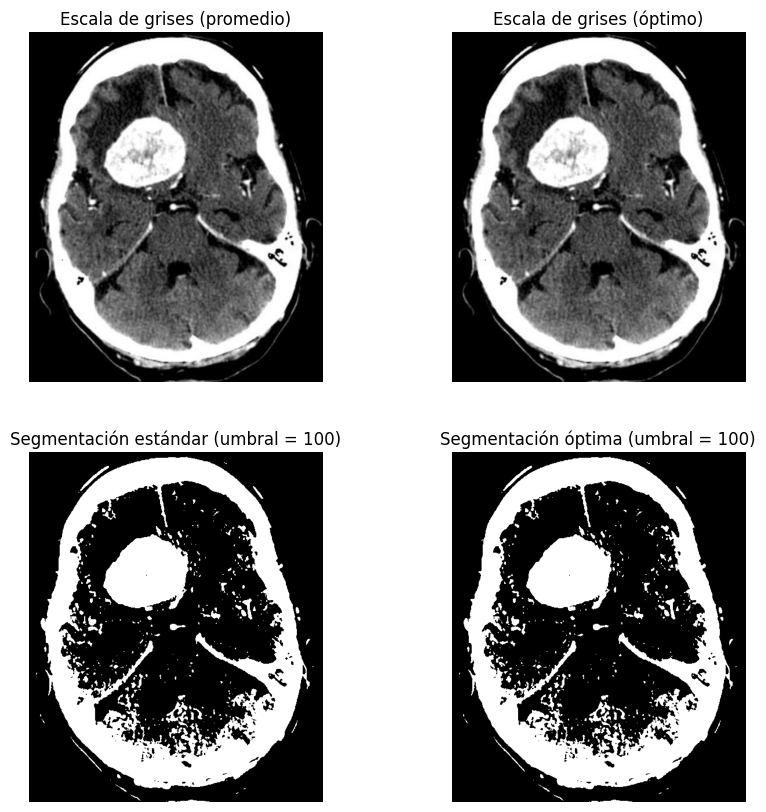

In [ ]:
# Crear imagen en escala de grises con pesos óptimos
gray_optimo = pesos_optimos[0] * R_norm + pesos_optimos[1] * G_norm + pesos_optimos[2] * B_norm

gray_optimo = (gray_optimo * 255).astype(np.uint8)

# Segmentación de la imagen
umbral = 100
_, seg_optimo = cv2.threshold(gray_optimo, umbral, 255, cv2.THRESH_BINARY)

# Mostrar resultados
plt.figure(figsize = (10, 10))
plt.subplot(2, 2, 1)
plt.imshow(gray_promedio, cmap = 'gray')
plt.title("Escala de grises (promedio)")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gray_optimo, cmap = 'gray')
plt.title("Escala de grises (óptimo)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(segmentada, cmap = 'gray')
plt.title(f"Segmentación estándar (umbral = {umbral})")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(seg_optimo, cmap = 'gray')
plt.title(f"Segmentación óptima (umbral = {umbral})")
plt.axis("off")
plt.show()

Una vez obtenidos los pesos óptimos, se arma la imagen en escala de grises combinando los canales RGB normalizados. El resultado se multiplica por 255 para regresar los valores al rango de 0 a 255.

Después, la imagen resultante se segmenta con "cv2.threshold()" utilizando el mismo valor de umbral previamente establecido (100).

Para finalizar, se realiza una comparación entre los resultados obtenidos haciendo uso de la segmentación sencilla y la segmentación óptima. Un detalle que se nota en ambos resultados son las pequeñas regiones blancas, las cuales como se mencionó anteriormente, se tratan de ruido.

**Eliminación de ruido**

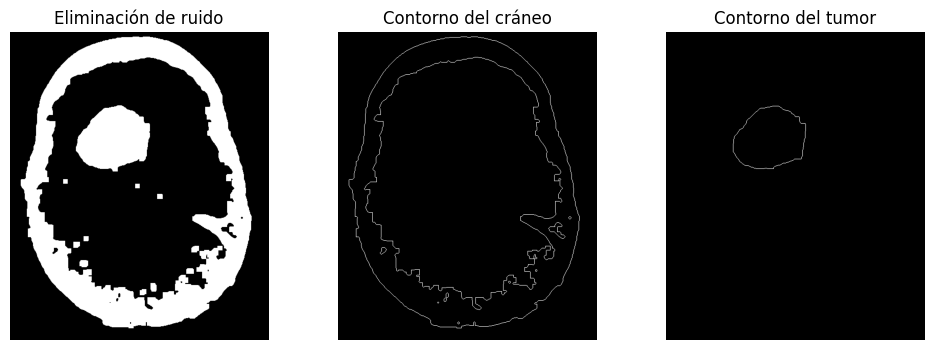

In [ ]:
# Filtro de mediana
filtro_mediana = cv2.medianBlur(seg_optimo, 5)

# Apertura morfológica
kernel = np.ones((5, 5), np.uint8)
seg_apertura = cv2.morphologyEx(filtro_mediana, cv2.MORPH_OPEN, kernel,
                                iterations=2)

# Identificación de regiones
num, etiquetas, stats, _ = cv2.connectedComponentsWithStats(seg_apertura)
orden = np.argsort(stats[1:, cv2.CC_STAT_AREA])[::-1] + 1

# Máscaras del craneo y del tumor
mascara_craneo = np.uint8(etiquetas == orden[0]) * 255
mascara_tumor = np.uint8(etiquetas == orden[1]) * 255

# Apertura adicional para el tumor
kernel_tumor = np.ones((13, 13), np.uint8)
mascara_tumor = cv2.morphologyEx(mascara_tumor, cv2.MORPH_OPEN, kernel_tumor)

# Contorno del cráneo
contornos_craneo, _ = cv2.findContours(mascara_craneo, cv2.RETR_LIST,
                                       cv2.CHAIN_APPROX_NONE)
imagen_craneo = np.zeros_like(mascara_craneo)
cv2.drawContours(imagen_craneo, contornos_craneo, -1, 255, 1)

# Contorno del tumor
contornos_tumor, _ = cv2.findContours(mascara_tumor, cv2.RETR_EXTERNAL,
                                      cv2.CHAIN_APPROX_NONE)
imagen_tumor = np.zeros_like(mascara_tumor)
cv2.drawContours(imagen_tumor, contornos_tumor, -1, 255, 1)

# Mostrar resultados
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(seg_apertura, cmap='gray')
plt.title("Eliminación de ruido")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_craneo, cmap='gray')
plt.title("Contorno del cráneo")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_tumor, cmap='gray')
plt.title("Contorno del tumor")
plt.axis("off")
plt.show()


Para eliminar el ruido de la imagen con segmentación óptima, se aplica primeramente un filtro de mediana 5x5 a través de "cv2.medianBlur()", el cual se encarga de cambiar cada píxel por la mediana de sus vecinos, eliminando los puntos blancos aislados más pequeños.

Después, se aplica una apertura morfológica con "cv2.morphologyEx()" con un kernel de 5x5 y dos iteraciones. Una apertura consiste en una erosión y una dilatación. La erosión elimina las regiones más pequeñas que el kernel y separa las uniones delgadas entre el tejido y las estructuras que nos interesan. Por su parte, la dilatación regresa a las regiones que quedaron a su tamaño original.

Se utiliza "cv2.connectedComponentsWithStats()" para la identificación de cada región blanca de la imagen y para obtener su área. La región más grande es la del cráneo y la segunda es del tumor. Con esto, se crearon dos máscaras binarias, descartando las demás regiones que se consideran ruido. A la máscara del tumor se le aplica una segunda apertura con un kernel de 13x13 para eliminar ciertos puntos blancos que aún se habían mantenido.

Para finalizar, los contornos se obtienen para cada máscara con "cv2.findContours()". Se utiliza "RETR_LIST" para el contorno del cráneo y "RETR_EXTERNAL" para el tumor. Los contornos se dibujan con "cv2.drawContours()" y se muestran los resultados con matplotlib.

**Cálculo área del tumor**

In [ ]:
# Calcular el área del tumor a partir de su contorno
area_tumor = cv2.contourArea(contornos_tumor[0])
print(f"Área del tumor: {area_tumor:.0f} px²")

Área del tumor: 13242 px²


Para realizar el cálculo del área del tumor se utilizó la función "cv2.contourArea()" el cual recibe el contorno que se obtuvo anteriormente. Esta función trata al contorno como un polígono y calcula el área que encierra.

Finalmente, se encontró que el área del tumor es de 13,242 píxeles.